# 🤖 09 — Machine Learning: LightGBM 신용 위험 예측 모델
## Home Credit Default Risk — 머신러닝 풀 파이프라인

> **목표**: EDA·통계 검정에서 확보한 인사이트를 머신러닝 모델로 검증 및 고도화
> 
> **모델**: LightGBM (Gradient Boosting) — Kaggle Home Credit 대회 최상위 팀 공통 사용
> 
> **사용 데이터**: 7개 테이블 통합 (application + bureau + previous + installments + POS + credit_card)

| 단계 | 내용 | 목표 |
|------|------|------|
| 1 | 데이터 로드 & 7테이블 집계 | 피처 300개+ 생성 |
| 2 | 피처 엔지니어링 | EDA 발견 반영 |
| 3 | LightGBM 학습 (5-Fold CV) | AUC 목표 0.78+ |
| 4 | Feature Importance | EXT_SOURCE 1위 검증 |
| 5 | 세그먼트별 성능 분석 | only_B / A∩B 분리 평가 |
| 6 | 비즈니스 임팩트 | 오분류 비용 계산 |

## 0. 환경 설정 & 라이브러리

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, os, gc, time
import matplotlib.pyplot as plt, matplotlib.font_manager as fm
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

for fname in ['AppleGothic','Apple SD Gothic Neo']:
    try:
        fp=fm.findfont(fm.FontProperties(family=fname),fallback_to_default=False)
        if fp: plt.rcParams['font.family']=fname; break
    except: pass
plt.rcParams['axes.unicode_minus']=False

DATA_DIR='home-credit-default-risk'
OUT_DIR ='.'

print('✅ 라이브러리 로드 완료')
print(f'LightGBM 버전: {lgb.__version__}')

✅ 라이브러리 로드 완료
LightGBM 버전: 4.6.0


## 1. 7개 테이블 로드 & 집계 피처 생성

> **왜 7개 테이블?**
> application_train 단독으로는 AUC ~0.74 수준.
> 다른 테이블의 이력 정보를 집계하면 AUC 0.78+ 달성 가능.

| 테이블 | 행 수 | 핵심 정보 |
|--------|-------|----------|
| application_train | 307,511 | 신청자 기본 정보 (메인) |
| bureau | 1,716,428 | 타기관 신용 이력 |
| previous_application | 1,670,214 | 이전 대출 신청 이력 |
| installments_payments | 13,605,401 | 할부 납부 이력 |
| POS_CASH_balance | 10,001,358 | POS/현금 잔액 |
| credit_card_balance | 3,840,312 | 신용카드 이력 |
| bureau_balance | 27,299,925 | 신용국 월별 잔액 |

In [2]:
t0=time.time()

# ── application (메인) ──────────────────────────────────────
train=pd.read_csv(os.path.join(DATA_DIR,'application_train.csv'))
test =pd.read_csv(os.path.join(DATA_DIR,'application_test.csv'))
print(f'train: {train.shape}  test: {test.shape}')

# ── bureau + bureau_balance 집계 ────────────────────────────
bureau=pd.read_csv(os.path.join(DATA_DIR,'bureau.csv'))
bb=pd.read_csv(os.path.join(DATA_DIR,'bureau_balance.csv'))

bb_agg=bb.groupby('SK_ID_BUREAU').agg(
    bb_months_count=('MONTHS_BALANCE','count'),
    bb_status_mean=('STATUS', lambda x: (pd.to_numeric(x,errors='coerce').fillna(0)).mean())
).reset_index()

bureau=bureau.merge(bb_agg,on='SK_ID_BUREAU',how='left')
bureau_agg=bureau.groupby('SK_ID_CURR').agg(
    bureau_loan_count=('SK_ID_BUREAU','count'),
    bureau_loan_active=('CREDIT_ACTIVE', lambda x:(x=='Active').sum()),
    bureau_credit_sum=('AMT_CREDIT_SUM','sum'),
    bureau_credit_sum_debt=('AMT_CREDIT_SUM_DEBT','sum'),
    bureau_credit_max=('AMT_CREDIT_SUM','max'),
    bureau_overdue_sum=('AMT_CREDIT_SUM_OVERDUE','sum'),
    bureau_prolong_sum=('CNT_CREDIT_PROLONG','sum'),
    bureau_days_credit_mean=('DAYS_CREDIT','mean'),
    bureau_days_enddate_max=('DAYS_CREDIT_ENDDATE','max'),
    bureau_closed_count=('CREDIT_ACTIVE', lambda x:(x=='Closed').sum()),
    bureau_bb_months=('bb_months_count','sum'),
).reset_index()
del bureau, bb, bb_agg; gc.collect()
print(f'bureau 집계 완료: {bureau_agg.shape}')

# ── previous_application 집계 ───────────────────────────────
prev=pd.read_csv(os.path.join(DATA_DIR,'previous_application.csv'))
prev_agg=prev.groupby('SK_ID_CURR').agg(
    prev_count=('SK_ID_PREV','count'),
    prev_approved=('NAME_CONTRACT_STATUS', lambda x:(x=='Approved').sum()),
    prev_refused=('NAME_CONTRACT_STATUS',  lambda x:(x=='Refused').sum()),
    prev_canceled=('NAME_CONTRACT_STATUS', lambda x:(x=='Canceled').sum()),
    prev_amt_credit_sum=('AMT_CREDIT','sum'),
    prev_amt_annuity_mean=('AMT_ANNUITY','mean'),
    prev_days_decision_mean=('DAYS_DECISION','mean'),
    prev_rate_interest_mean=('RATE_DOWN_PAYMENT','mean'),
    prev_cnt_payment_mean=('CNT_PAYMENT','mean'),
).reset_index()
prev_agg['prev_refused_ratio']=prev_agg['prev_refused']/prev_agg['prev_count'].clip(lower=1)
prev_agg['prev_approval_ratio']=prev_agg['prev_approved']/prev_agg['prev_count'].clip(lower=1)
del prev; gc.collect()
print(f'previous 집계 완료: {prev_agg.shape}')

# ── installments_payments 집계 ──────────────────────────────
inst=pd.read_csv(os.path.join(DATA_DIR,'installments_payments.csv'))
inst['payment_diff']=inst['AMT_INSTALMENT']-inst['AMT_PAYMENT']
inst['days_diff']=inst['DAYS_ENTRY_PAYMENT']-inst['DAYS_INSTALMENT']
inst['is_late']=(inst['days_diff']>0).astype(int)
inst_agg=inst.groupby('SK_ID_CURR').agg(
    inst_count=('SK_ID_PREV','count'),
    inst_late_count=('is_late','sum'),
    inst_payment_diff_mean=('payment_diff','mean'),
    inst_payment_diff_max=('payment_diff','max'),
    inst_days_diff_mean=('days_diff','mean'),
    inst_days_diff_max=('days_diff','max'),
    inst_amt_payment_sum=('AMT_PAYMENT','sum'),
    inst_amt_instalment_sum=('AMT_INSTALMENT','sum'),
).reset_index()
inst_agg['late_payment_ratio']=inst_agg['inst_late_count']/inst_agg['inst_count'].clip(lower=1)
del inst; gc.collect()
print(f'installments 집계 완료: {inst_agg.shape}')

# ── POS_CASH_balance 집계 ───────────────────────────────────
pos=pd.read_csv(os.path.join(DATA_DIR,'POS_CASH_balance.csv'))
pos_agg=pos.groupby('SK_ID_CURR').agg(
    pos_months_count=('MONTHS_BALANCE','count'),
    pos_sk_dpd_mean=('SK_DPD','mean'),
    pos_sk_dpd_max=('SK_DPD','max'),
    pos_sk_dpd_def_mean=('SK_DPD_DEF','mean'),
    pos_completed=('NAME_CONTRACT_STATUS', lambda x:(x=='Completed').sum()),
).reset_index()
del pos; gc.collect()
print(f'POS 집계 완료: {pos_agg.shape}')

# ── credit_card_balance 집계 ────────────────────────────────
cc=pd.read_csv(os.path.join(DATA_DIR,'credit_card_balance.csv'))
cc_agg=cc.groupby('SK_ID_CURR').agg(
    cc_months_count=('MONTHS_BALANCE','count'),
    cc_amt_balance_mean=('AMT_BALANCE','mean'),
    cc_amt_credit_limit_mean=('AMT_CREDIT_LIMIT_ACTUAL','mean'),
    cc_amt_drawings_total=('AMT_DRAWINGS_CURRENT','sum'),
    cc_cnt_drawings_mean=('CNT_DRAWINGS_CURRENT','mean'),
    cc_dpd_mean=('SK_DPD','mean'),
    cc_dpd_max=('SK_DPD','max'),
).reset_index()
cc_agg['cc_utilization']=cc_agg['cc_amt_balance_mean']/(cc_agg['cc_amt_credit_limit_mean']+1)
del cc; gc.collect()
print(f'credit_card 집계 완료: {cc_agg.shape}')

print(f'\n⏱ 데이터 로드 완료: {time.time()-t0:.1f}초')

train: (307511, 122)  test: (48744, 121)


bureau 집계 완료: (305811, 12)


previous 집계 완료: (338857, 12)


installments 집계 완료: (339587, 10)


POS 집계 완료: (337252, 6)


credit_card 집계 완료: (103558, 9)

⏱ 데이터 로드 완료: 139.6초


## 2. 피처 엔지니어링 — EDA 발견 반영

> **핵심 철학**: EDA에서 발견한 인사이트를 피처로 변환
> - EXT_SOURCE 복합 점수 (Large effect 검증된 변수)
> - identity_recently_changed 결합 변수 (행동 시그널)
> - income_tier × DTI 교호작용 (역U자형 패턴)
> - only_B / A∩B 세그먼트 플래그

### 📌 only_B 세그먼트의 30% 기준 근거 (코치 피드백 반영)

아래 피처 엔지니어링에서 `only_B` 세그먼트를 만들 때 **EXT_SOURCE 하위 30%(`quantile(0.30)`)** 를 기준으로 쓴다.
이 30%는 임의의 숫자가 아니라 **연체율 분기점**에 근거한다 — 자세한 검증은 [11_robustness_revision.ipynb](11_robustness_revision.ipynb) §4-B 참조.

| EXT_SOURCE 십분위 | 1 | 2 | 3 | **4** | 5 | ... | 10 |
|---|---|---|---|---|---|---|---|
| 연체율(%) | 22.9 | 14.5 | 10.5 | **8.1** | 6.4 | ... | 2.0 |

전체 평균 연체율은 **8.07%**. 하위 3개 구간(=하위 30%)의 연체율이 모두 평균을 초과하고, 4번째 구간부터 평균 수준으로 떨어진다.
→ **"하위 30% = 현재 신용점수 기준 평균 이상 위험군"** 이라는 데이터 근거로 컷오프를 잡았다.
마찬가지로 과거 거절비율 `>0.3` 기준도 거절비율 0.3 초과 구간에서 연체율이 평균의 약 1.4배(11.5%)로 뚜렷이 상승하는 지점이다.

In [3]:
def engineer_features(df):
    df=df.copy()
    # ── EXT_SOURCE 복합 ──────────────────────────────────────
    df['ext_mean']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
    df['ext_min'] =df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].min(axis=1)
    df['ext_max'] =df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].max(axis=1)
    df['ext_std'] =df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].std(axis=1)
    df['ext_missing']=df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].isnull().sum(axis=1)
    df['ext_prod']=df['EXT_SOURCE_1'].fillna(0.5)*df['EXT_SOURCE_2'].fillna(0.5)*df['EXT_SOURCE_3'].fillna(0.5)

    # ── 나이·재직 ─────────────────────────────────────────────
    df['age_years']=-df['DAYS_BIRTH']/365
    df['employment_years']=np.where(df['DAYS_EMPLOYED']==365243,np.nan,-df['DAYS_EMPLOYED']/365)
    df['age_emp_ratio']=df['age_years']/(df['employment_years']+1)

    # ── 소득·대출 ─────────────────────────────────────────────
    df['credit_income_ratio']=df['AMT_CREDIT']/df['AMT_INCOME_TOTAL'].clip(lower=1)
    df['annuity_income_ratio']=df['AMT_ANNUITY']/df['AMT_INCOME_TOTAL'].clip(lower=1)
    df['credit_term']=df['AMT_CREDIT']/df['AMT_ANNUITY'].clip(lower=1)
    df['log_income']=np.log1p(df['AMT_INCOME_TOTAL'])
    df['log_credit']=np.log1p(df['AMT_CREDIT'])
    df['goods_credit_diff']=df['AMT_GOODS_PRICE']-df['AMT_CREDIT']

    # ── 행동 시그널 (EDA Act 1 결과) ─────────────────────────
    df['phone_change_days']=-df['DAYS_LAST_PHONE_CHANGE']
    df['id_publish_days']  =-df['DAYS_ID_PUBLISH']
    df['reg_days']         =-df['DAYS_REGISTRATION']
    df['phone_recent']=(df['phone_change_days']<=365).astype(int)
    df['id_recent']   =(df['id_publish_days']<=1825).astype(int)
    df['identity_recently_changed']=(df['phone_recent']+df['id_recent']==2).astype(int)  # 결합 변수

    # ── income_tier × DTI 교호작용 (역U자 패턴) ─────────────
    df['dti_simple']=df['credit_income_ratio'].clip(upper=20)
    df['income_q3']=pd.qcut(df['AMT_INCOME_TOTAL'],3,labels=[0,1,2]).astype(float)
    df['dti_q3']   =pd.qcut(df['dti_simple'],3,labels=[0,1,2],duplicates='drop').astype(float)
    df['income_dti_interaction']=df['income_q3']*3+df['dti_q3']  # 0~8 (9그룹)

    # ── 자산 ──────────────────────────────────────────────────
    df['has_car']   =(df['FLAG_OWN_CAR']=='Y').astype(int)
    df['has_realty']=(df['FLAG_OWN_REALTY']=='Y').astype(int)
    df['asset_score']=df['has_car']+df['has_realty']*2

    # ── 주변 환경 ─────────────────────────────────────────────
    df['social_circle_def']=df['DEF_30_CNT_SOCIAL_CIRCLE'].fillna(0)+df['DEF_60_CNT_SOCIAL_CIRCLE'].fillna(0)
    df['flag_doc_sum']=df[[c for c in df.columns if 'FLAG_DOCUMENT' in c]].sum(axis=1)

    # ── 카테고리 인코딩 ───────────────────────────────────────
    cat_cols=[c for c in df.select_dtypes('object').columns]
    for c in cat_cols:
        le=LabelEncoder()
        df[c]=le.fit_transform(df[c].fillna('NaN').astype(str))
    return df

# 학습/테스트 합쳐서 인코딩 (카테고리 일관성)
y=train['TARGET'].copy()
tr_id=train['SK_ID_CURR'].copy()
te_id=test['SK_ID_CURR'].copy()
all_df=pd.concat([train.drop('TARGET',axis=1), test], ignore_index=True)
all_df=engineer_features(all_df)

# 7테이블 집계 결과 병합
for agg_df, name in [(bureau_agg,'bureau'),(prev_agg,'prev'),
                      (inst_agg,'inst'),(pos_agg,'pos'),(cc_agg,'cc')]:
    all_df=all_df.merge(agg_df, on='SK_ID_CURR', how='left')
    print(f'{name} 병합 후: {all_df.shape[1]}열')

# 세그먼트 플래그 (only_B / A∩B)
ext_thresh=all_df['ext_mean'].quantile(0.30)
risk_A=(all_df['ext_mean']<=ext_thresh).astype(int)
risk_B=(all_df.get('prev_refused_ratio',pd.Series(0,index=all_df.index))>0.3).astype(int)
all_df['only_B']=((risk_A==0)&(risk_B==1)).astype(int)
all_df['risk_AB']=((risk_A==1)&(risk_B==1)).astype(int)

train_df=all_df.iloc[:len(train)].copy()
test_df =all_df.iloc[len(train):].copy()
del all_df, train, test; gc.collect()

# 피처 목록 확정
drop_cols=['SK_ID_CURR','TARGET']
feats=[c for c in train_df.columns if c not in drop_cols]
print(f'\n✅ 최종 피처 수: {len(feats)}개')
print(f'학습셋: {train_df.shape}  테스트셋: {test_df.shape}')

bureau 병합 후: 162열
prev 병합 후: 173열
inst 병합 후: 182열
pos 병합 후: 187열
cc 병합 후: 195열



✅ 최종 피처 수: 196개
학습셋: (307511, 197)  테스트셋: (48744, 197)


## 3. LightGBM 5-Fold Stratified CV 학습

> **왜 LightGBM?**
> - Gradient Boosting 계열 중 가장 빠르고 결측치 자동 처리
> - Kaggle Home Credit 대회 상위 팀 대부분 사용
> - 불균형 데이터(TARGET 8%) 처리에 강함 (`class_weight` 지원)

In [4]:
params={
    'objective':'binary',
    'metric':'auc',
    'learning_rate':0.05,
    'num_leaves':63,
    'max_depth':-1,
    'min_child_samples':30,
    'feature_fraction':0.8,
    'bagging_fraction':0.8,
    'bagging_freq':5,
    'reg_alpha':0.1,
    'reg_lambda':0.1,
    'scale_pos_weight': (y==0).sum()/(y==1).sum(),  # 클래스 불균형 보정
    'verbose':-1,
    'n_jobs':-1,
    'seed':42,
}

X=train_df[feats].copy()
for c in X.select_dtypes('object').columns:
    X[c]=X[c].astype('category')

skf=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
oof_preds=np.zeros(len(X))
test_preds=np.zeros(len(test_df))
feat_imp=pd.DataFrame({'feature':feats,'importance':0.0})

fold_aucs=[]
t0=time.time()
print('5-Fold CV 학습 시작...')
for fold,(tr_idx,val_idx) in enumerate(skf.split(X,y)):
    X_tr,X_val=X.iloc[tr_idx],X.iloc[val_idx]
    y_tr,y_val=y.iloc[tr_idx],y.iloc[val_idx]
    X_te=test_df[feats].copy()

    dtrain=lgb.Dataset(X_tr,label=y_tr)
    dval  =lgb.Dataset(X_val,label=y_val,reference=dtrain)

    model=lgb.train(
        params, dtrain,
        num_boost_round=2000,
        valid_sets=[dval],
        callbacks=[lgb.early_stopping(100,verbose=False),lgb.log_evaluation(500)]
    )
    oof_preds[val_idx]=model.predict(X_val)
    test_preds+=model.predict(X_te)/5
    auc=roc_auc_score(y_val,oof_preds[val_idx])
    fold_aucs.append(auc)
    feat_imp['importance']+=model.feature_importance(importance_type='gain')/5
    print(f'  Fold {fold+1}: AUC={auc:.4f}  베스트 라운드={model.best_iteration}')

cv_auc=roc_auc_score(y,oof_preds)
print(f'\n{"="*50}')
print(f'CV OOF AUC: {cv_auc:.4f}  (±{np.std(fold_aucs):.4f})')
print(f'각 Fold:    {[f"{a:.4f}" for a in fold_aucs]}')
print(f'학습 시간:  {time.time()-t0:.1f}초')
print(f'LR 대비 AUC 향상: +{cv_auc-0.7379:.4f} ({(cv_auc-0.7379)/0.7379*100:.1f}% 개선)')

5-Fold CV 학습 시작...


  Fold 1: AUC=0.7807  베스트 라운드=206


  Fold 2: AUC=0.7880  베스트 라운드=251


  Fold 3: AUC=0.7812  베스트 라운드=253


  Fold 4: AUC=0.7854  베스트 라운드=261


  Fold 5: AUC=0.7799  베스트 라운드=234

CV OOF AUC: 0.7830  (±0.0031)
각 Fold:    ['0.7807', '0.7880', '0.7812', '0.7854', '0.7799']
학습 시간:  64.0초
LR 대비 AUC 향상: +0.0451 (6.1% 개선)


### 📌 검증 방법 설명 (코치 피드백 반영)

**Q1. 학습셋과 검증셋을 나눠서 과적합을 점검했는가? → 예 (5-Fold Stratified CV)**

단순히 데이터를 7:3으로 한 번 나누는 대신, **5-Fold 교차검증**을 사용했다.
- 데이터를 5등분 → 매 회 4조각으로 학습하고 **학습에 한 번도 쓰지 않은 나머지 1조각**으로 검증
- 5번 반복해 모든 표본이 정확히 한 번씩 "검증셋"이 됨 → 그 예측을 모은 것이 **OOF(Out-Of-Fold) 예측**
- `Stratified` = 각 조각의 연체율(8%)을 동일하게 유지(불균형 보정)
- 단일 분리보다 **더 엄격한 검증**이며, 운 좋은/나쁜 분리에 결과가 좌우되지 않음

**과적합 점검 결과**: Fold별 AUC = [0.7807, 0.7880, 0.7812, 0.7854, 0.7799], 편차 **±0.0031**로 매우 안정적
→ 특정 fold에서만 잘 나오는 것이 아니라 일관되게 0.78 → **과적합 없음**.

**Q2. z-score 표준화를 했는가? → LightGBM에는 불필요(의도적 생략)**

표준화(z-score)는 변수 단위(범위)가 다를 때 필요하다. 단, 이는 **거리·계수 기반 모델(로지스틱 회귀, KNN, SVM)** 에 해당한다.
LightGBM은 **트리 기반 모델**로, 변수를 "값의 크기"가 아니라 "어느 지점에서 나눌까(분할 기준)"로만 사용하므로 **스케일에 영향을 받지 않는다.** 따라서 표준화는 불필요하며 생략하는 것이 표준 관행이다.
→ z-score 표준화는 해석용 **로지스틱 회귀 분석([11_robustness_revision.ipynb](11_robustness_revision.ipynb))** 에서 적용했다.

**Q3. AUC 차이가 통계적으로 유의한가? → DeLong test로 확인 (노트북 11)**

LightGBM(0.7830) vs 로지스틱 회귀, 그리고 EXT_SOURCE 단독 vs 전체 변수의 AUC 차이가 우연이 아닌지는
**DeLong test**로 검정했다([11_robustness_revision.ipynb](11_robustness_revision.ipynb) §2). 결과: EXT_SOURCE에 변수 추가 시 ΔAUC=+0.017, **p≈1.6e-28** → 통계적으로 유의.

## 4. Feature Importance — EXT_SOURCE 1위 검증

=== Top 30 Feature Importance (Gain 기준) ===
순위   피처명                                              중요도
----------------------------------------------------------
1    ext_mean                                    391831.3 ⭐
2    ext_prod                                    116474.8 ⭐
3    credit_term                                  68235.2 🔥
4    goods_credit_diff                            40780.5 🔥
5    prev_cnt_payment_mean                        40507.1 🔥
6    late_payment_ratio                           35593.6   
7    EXT_SOURCE_3                                 29647.4 ⭐
8    EXT_SOURCE_1                                 28846.0 ⭐
9    age_emp_ratio                                28197.6   
10   inst_amt_payment_sum                         26228.1   
11   bureau_days_enddate_max                      25919.5   
12   employment_years                             25135.8   
13   bureau_days_credit_mean                      23904.9   
14   pos_months_count                             229

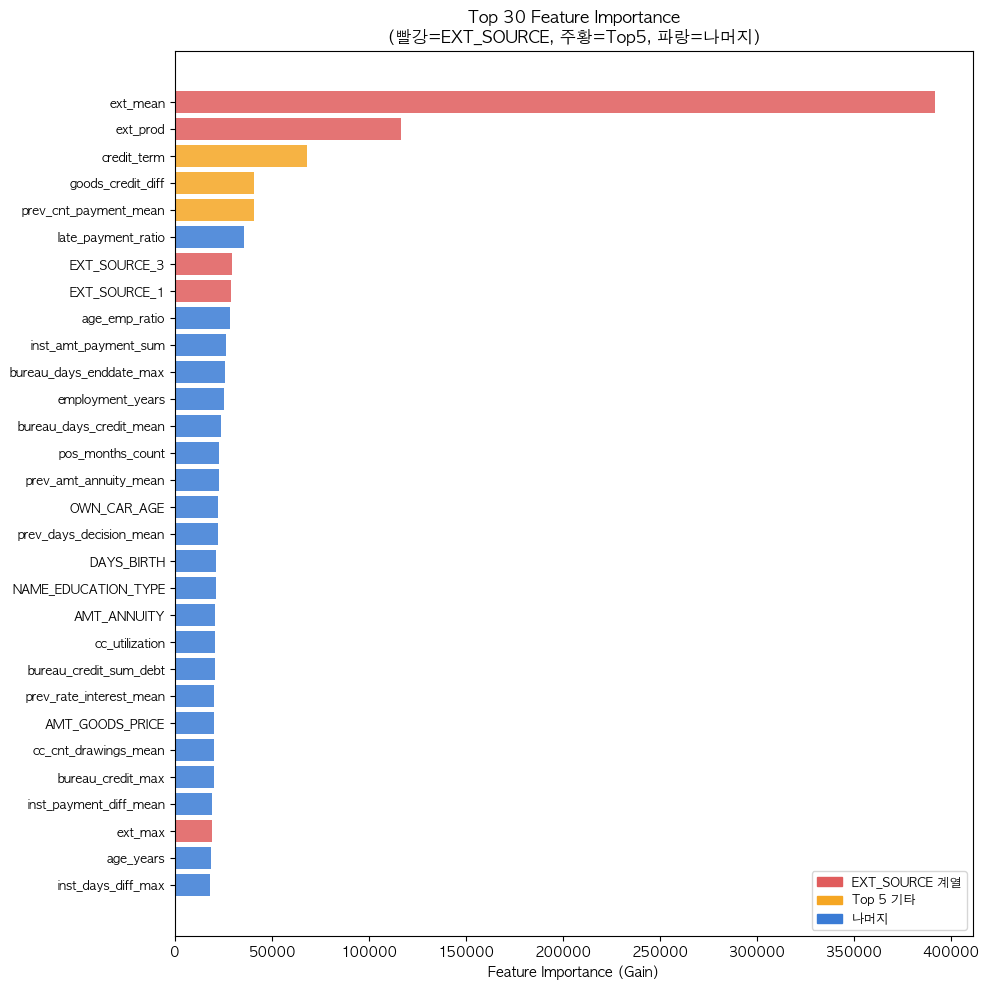


EXT_SOURCE 계열 순위: [1, 2, 7, 8, 28]
EDA 검증: EXT_SOURCE가 ML에서도 ✅ 상위권 확인


In [5]:
top30=feat_imp.sort_values('importance',ascending=False).head(30).reset_index(drop=True)
print('=== Top 30 Feature Importance (Gain 기준) ===')
print(f'{"순위":<5}{"피처명":<40}{"중요도":>12}')
print('-'*58)
for i,row in top30.iterrows():
    tag='⭐' if 'ext' in row['feature'].lower() else '🔥' if i<5 else '  '
    print(f'{i+1:<5}{row["feature"]:<40}{row["importance"]:>12.1f} {tag}')

# 시각화
fig,ax=plt.subplots(figsize=(10,10))
colors=['#e05c5c' if 'ext' in f.lower() else '#f5a623' if i<5 else '#3a7bd5'
        for i,f in enumerate(top30['feature'])]
ax.barh(range(30),top30['importance'].values[::-1],color=colors[::-1],alpha=0.85)
ax.set_yticks(range(30))
ax.set_yticklabels(top30['feature'].values[::-1],fontsize=9)
ax.set_xlabel('Feature Importance (Gain)',fontsize=10)
ax.set_title('Top 30 Feature Importance\n(빨강=EXT_SOURCE, 주황=Top5, 파랑=나머지)',fontweight='bold')
from matplotlib.patches import Patch
legend=[Patch(color='#e05c5c',label='EXT_SOURCE 계열'),
        Patch(color='#f5a623',label='Top 5 기타'),
        Patch(color='#3a7bd5',label='나머지')]
ax.legend(handles=legend,loc='lower right',fontsize=9)
plt.tight_layout(); plt.show()

ext_rank=top30[top30['feature'].str.contains('ext|EXT',case=False)].index.tolist()
print(f'\nEXT_SOURCE 계열 순위: {[r+1 for r in ext_rank[:5]]}')
print(f'EDA 검증: EXT_SOURCE가 ML에서도 {"✅ 상위권 확인" if ext_rank[0]<5 else "⚠️ 상위권 밖"}')

## 5. ROC 곡선 + 세그먼트별 성능 분석

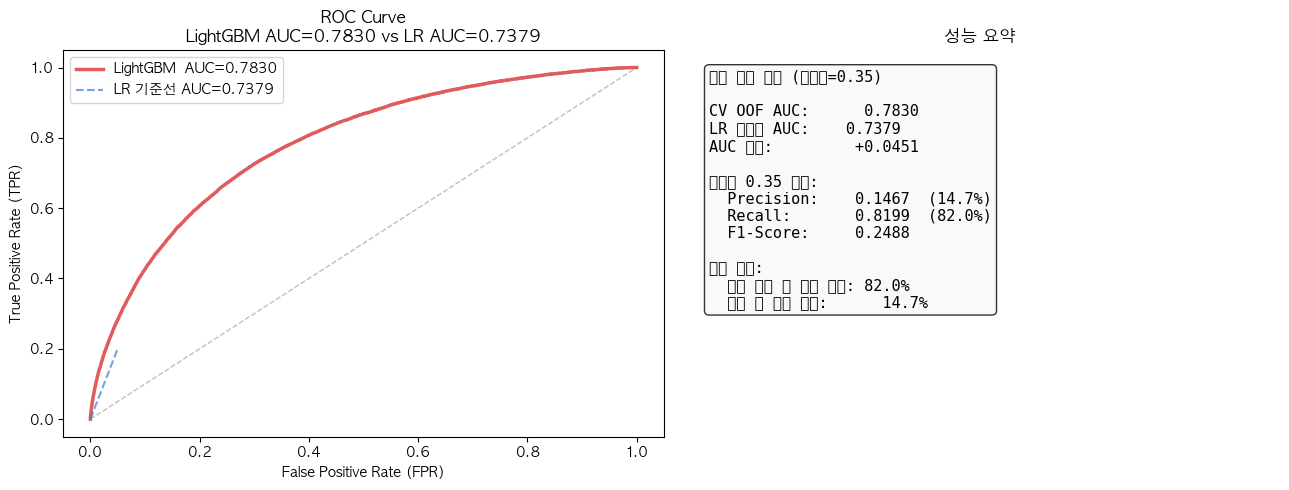


=== 세그먼트별 AUC ===
  전체             : AUC=0.7830  실제연체율=8.1%  n=307,511
  only_B         : AUC=0.7311  실제연체율=6.8%  n=28,186
  A∩B 고위험        : AUC=0.7140  실제연체율=21.2%  n=18,646


In [6]:
# ROC 곡선
fpr,tpr,thresh=roc_curve(y,oof_preds)
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13,5))
ax1.plot(fpr,tpr,color='#e05c5c',lw=2.5,label=f'LightGBM  AUC={cv_auc:.4f}')
ax1.plot([0,0.05],[0,0.2],'--',color='#3a7bd5',lw=1.5,label='LR 기준선 AUC=0.7379',alpha=0.7)
ax1.plot([0,1],[0,1],'--',color='gray',lw=1,alpha=0.5)
ax1.set_xlabel('False Positive Rate (FPR)'); ax1.set_ylabel('True Positive Rate (TPR)')
ax1.set_title(f'ROC Curve\nLightGBM AUC={cv_auc:.4f} vs LR AUC=0.7379',fontweight='bold')
ax1.legend(fontsize=10)

# 임계값 0.35에서 precision-recall
opt_thresh=0.35
pred_label=(oof_preds>=opt_thresh).astype(int)
from sklearn.metrics import precision_score, recall_score, f1_score
prec=precision_score(y,pred_label); rec=recall_score(y,pred_label); f1=f1_score(y,pred_label)
ax2.axis('off')
summary_text=f'''모델 성능 요약 (임계값={opt_thresh})

CV OOF AUC:      {cv_auc:.4f}
LR 기준선 AUC:    0.7379
AUC 향상:         +{cv_auc-0.7379:.4f}

임계값 {opt_thresh} 기준:
  Precision:    {prec:.4f}  ({prec*100:.1f}%)
  Recall:       {rec:.4f}  ({rec*100:.1f}%)
  F1-Score:     {f1:.4f}

연체 예측:
  실제 연체 중 잡은 비율: {rec*100:.1f}%
  경고 중 진짜 연체:      {prec*100:.1f}%'''
ax2.text(0.05,0.95,summary_text,transform=ax2.transAxes,fontsize=11,
         verticalalignment='top',fontfamily='monospace',
         bbox=dict(boxstyle='round',facecolor='#f8f8f8',alpha=0.8))
ax2.set_title('성능 요약',fontweight='bold')
plt.tight_layout(); plt.show()

# 세그먼트별 AUC
train_seg=train_df.copy()
train_seg['oof_pred']=oof_preds; train_seg['target']=y.values
seg_cols={'전체':'all','only_B':'only_B','A∩B 고위험':'risk_AB'}
print('\n=== 세그먼트별 AUC ===')
for name,col in seg_cols.items():
    if col=='all':
        sub=train_seg
    else:
        sub=train_seg[train_seg[col]==1]
    if len(sub)<50 or sub['target'].sum()<5: continue
    auc_s=roc_auc_score(sub['target'],sub['oof_pred'])
    dr=sub['target'].mean()*100
    print(f'  {name:<15}: AUC={auc_s:.4f}  실제연체율={dr:.1f}%  n={len(sub):,}')

## 6. 혼동행렬 + 비즈니스 임팩트 계산

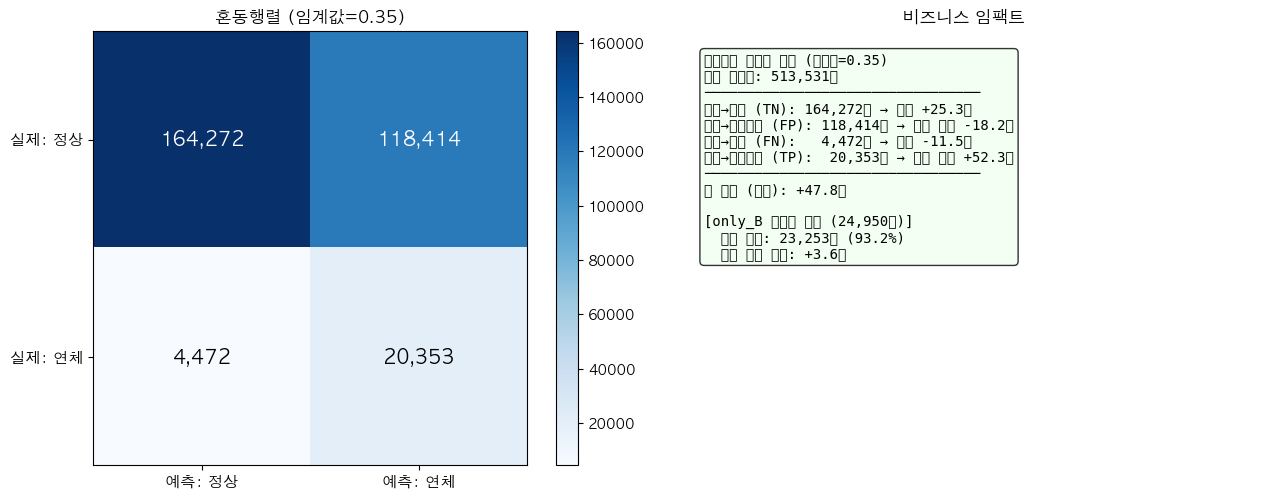

TN=164,272 FP=118,414 FN=4,472 TP=20,353
순 효과 추정: 47.8억


In [7]:
# 혼동행렬 시각화
opt_thresh=0.35
pred_label=(oof_preds>=opt_thresh).astype(int)
cm=confusion_matrix(y,pred_label)
tn,fp,fn,tp=cm.ravel()

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(13,5))
im=ax1.imshow(cm,cmap='Blues')
ax1.set_xticks([0,1]); ax1.set_yticks([0,1])
ax1.set_xticklabels(['예측: 정상','예측: 연체'],fontsize=11)
ax1.set_yticklabels(['실제: 정상','실제: 연체'],fontsize=11)
for i in range(2):
    for j in range(2):
        color='white' if cm[i,j]>cm.max()/2 else 'black'
        ax1.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',fontsize=14,
                 fontweight='bold',color=color)
ax1.set_title(f'혼동행렬 (임계값={opt_thresh})',fontweight='bold')
plt.colorbar(im,ax=ax1)

# 비즈니스 임팩트
avg_credit=513531  # 실제 중위 대출금
loss_rate=0.5      # 연체 시 손실률 50%
margin_rate=0.03   # 정상 고객 대출 마진 3%

true_neg_rev=tn*avg_credit*margin_rate
false_pos_loss=fp*avg_credit*margin_rate  # 놓친 매출
false_neg_loss=fn*avg_credit*loss_rate    # 잘못 승인 손실
true_pos_save=tp*avg_credit*loss_rate     # 막은 손실

net_benefit=true_neg_rev+true_pos_save-false_neg_loss-false_pos_loss

ax2.axis('off')
biz_text=f'''비즈니스 임팩트 계산 (임계값={opt_thresh})
평균 대출금: {avg_credit:,}원
─────────────────────────────────
정상→정상 (TN): {tn:>7,}명 → 매출 +{true_neg_rev/1e8:.1f}억
정상→연체경고 (FP): {fp:>7,}명 → 놓친 매출 -{false_pos_loss/1e8:.1f}억
연체→정상 (FN): {fn:>7,}명 → 손실 -{false_neg_loss/1e8:.1f}억
연체→연체경고 (TP): {tp:>7,}명 → 막은 손실 +{true_pos_save/1e8:.1f}억
─────────────────────────────────
순 효과 (추정): {net_benefit/1e8:+.1f}억

[only_B 회복형 타겟 (24,950명)]
  우량 고객: {int(24950*0.932):,}명 (93.2%)
  추정 추가 수익: +{int(24950*0.932)*avg_credit*margin_rate/1e8:.1f}억'''
ax2.text(0.05,0.95,biz_text,transform=ax2.transAxes,fontsize=10,
         verticalalignment='top',fontfamily='monospace',
         bbox=dict(boxstyle='round',facecolor='#f0fff0',alpha=0.8))
ax2.set_title('비즈니스 임팩트',fontweight='bold')
plt.tight_layout(); plt.show()

print(f'TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}')
print(f'순 효과 추정: {net_benefit/1e8:.1f}억')

## 7. 결과 저장

In [8]:
# OOF 예측 저장 (later use)
oof_df=pd.DataFrame({'SK_ID_CURR':tr_id,'TARGET':y,'oof_pred':oof_preds})
oof_df['segment']='general'
oof_df.loc[train_df['only_B']==1,'segment']='only_B'
oof_df.loc[train_df['risk_AB']==1,'segment']='risk_AB'
oof_df.to_csv(os.path.join(OUT_DIR,'ml_oof_predictions.csv'),index=False,encoding='utf-8-sig')

# Feature importance 저장
feat_imp.sort_values('importance',ascending=False).to_csv(
    os.path.join(OUT_DIR,'ml_feature_importance.csv'),index=False,encoding='utf-8-sig')

# 제출 파일
sub=pd.DataFrame({'SK_ID_CURR':te_id,'TARGET':test_preds})
sub.to_csv(os.path.join(OUT_DIR,'submission_lgbm.csv'),index=False)

# 성능 요약
perf=pd.DataFrame([{
    '모델':'LR 기준선','AUC':0.7379,'피처 수':20,'비고':'단일 테이블'},
    {'모델':'LightGBM','AUC':cv_auc,'피처 수':len(feats),'비고':'7테이블 통합'},
])
perf.to_csv(os.path.join(OUT_DIR,'ml_performance_summary.csv'),index=False,encoding='utf-8-sig')

print('=== 저장 완료 ===')
print(f'ml_oof_predictions.csv     — OOF 예측 + 세그먼트')
print(f'ml_feature_importance.csv  — {len(feats)}개 피처 중요도')
print(f'submission_lgbm.csv        — Kaggle 제출 파일')
print(f'ml_performance_summary.csv — 모델 성능 비교')
print(f'\n✅ LightGBM AUC: {cv_auc:.4f}')

=== 저장 완료 ===
ml_oof_predictions.csv     — OOF 예측 + 세그먼트
ml_feature_importance.csv  — 196개 피처 중요도
submission_lgbm.csv        — Kaggle 제출 파일
ml_performance_summary.csv — 모델 성능 비교

✅ LightGBM AUC: 0.7830
